# test_v2 — `test.ipynb` 수정본

원본 `C:\t_project_1_1\test.ipynb`은 원본 CSV 전체(260,601행)를 읽었습니다. 여기에는 팀 `final_holdout` 52,121행의 정답도 포함됩니다.
팀 규칙상 홀드아웃의 입력-정답 관계는 탐색하지 않으므로, 이 복사본은 **팀 development 208,480행만** 읽습니다.
원본 셀 28의 `train_test_split`(전체 데이터 8:2 분할)은 팀 분할과 다르고 이후에 쓰이지 않아 삭제했습니다.
원본 셀 24의 `2grade=` 키워드 인자는 SyntaxError라서, 같은 열 이름을 `**{"2grade": ...}` 형태로 넘기도록 고쳤습니다.

분석 코드는 원본과 같고, 바뀐 것은 데이터 경로와 저장 경로뿐입니다. 그래서 건수와 비율 숫자는 원본과 다르게 나옵니다.

In [1]:
# [v2] 팀 development 데이터만 사용 (final_holdout 제외)
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocess.py").exists())
DEV_CSV = REPO / "data" / "development.csv"   # 원본 CSV에서 팀 홀드아웃 52,121행을 뺀 208,480행
OUT_DIR = REPO / "outputs" / "t_project_v2" / "test"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("데이터:", DEV_CSV)
print("저장 폴더:", OUT_DIR)

데이터: C:\Users\jhj31\project_1\earthquake\data\development.csv
저장 폴더: C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\test


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# 한글 폰트 설정 (Windows)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 데이터 출력 설정
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

# CSV 파일 경로
file_path = DEV_CSV  # [v2] 팀 development

# 데이터 불러오기
df_main = pd.read_csv(file_path)

# 원본 보존
df = df_main.copy()

print("CSV 로딩 완료")
print("데이터 크기:", df.shape)

display(df.head())


CSV 로딩 완료
데이터 크기: (208480, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,4,30,266,1224,1,25,5,2,t,r,n,f,j,s,d,0,1,0,0,0,0,0,0,0,0,0,v,0,0,0,0,0,0,0,0,0,0,0,0,2
1,8,17,409,12182,2,0,13,7,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
2,12,17,716,7056,2,5,12,6,o,r,q,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,16,4,651,105,2,80,5,4,n,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,25,26,1132,6645,2,0,6,6,t,w,n,f,x,s,d,0,0,0,0,0,0,1,0,0,0,0,a,1,0,0,0,0,0,0,0,0,0,0,0,1


In [3]:

# 1. 상위 5개 행
display(df.head())

# 2. 하위 5개 행
display(df.tail())

# 3. 전체 데이터 크기
print("행 수:", df.shape[0])
print("열 수:", df.shape[1])

# 4. 전체 컬럼명
print(df.columns.tolist())

# 5. 컬럼별 데이터 타입
print(df.dtypes)

# 6. 데이터 구조, Non-Null, 메모리
df.info(memory_usage="deep")

# 7. 수치형 데이터 요약 통계
display(df.describe().T)

# 8. 범주형 데이터 요약 통계
display(df.describe(include=["object", "str", "category"]).T)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,4,30,266,1224,1,25,5,2,t,r,n,f,j,s,d,0,1,0,0,0,0,0,0,0,0,0,v,0,0,0,0,0,0,0,0,0,0,0,0,2
1,8,17,409,12182,2,0,13,7,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
2,12,17,716,7056,2,5,12,6,o,r,q,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,16,4,651,105,2,80,5,4,n,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,25,26,1132,6645,2,0,6,6,t,w,n,f,x,s,d,0,0,0,0,0,0,1,0,0,0,0,a,1,0,0,0,0,0,0,0,0,0,0,0,1


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
208475,1052921,4,1235,4976,3,25,9,7,t,r,q,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
208476,1052926,20,1359,1810,2,5,7,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,1,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
208477,1052929,17,303,9803,3,55,10,6,t,r,q,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
208478,1052931,17,1240,6305,3,35,4,4,t,r,n,f,q,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
208479,1052934,8,374,698,2,45,5,5,t,r,n,f,q,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


행 수: 208480
열 수: 40
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'legal_ownership_status', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_seco

<class 'pandas.DataFrame'>
RangeIndex: 208480 entries, 0 to 208479
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             208480 non-null  int64
 1   geo_level_1_id                          208480 non-null  int64
 2   geo_level_2_id                          208480 non-null  int64
 3   geo_level_3_id                          208480 non-null  int64
 4   count_floors_pre_eq                     208480 non-null  int64
 5   age                                     208480 non-null  int64
 6   area_percentage                         208480 non-null  int64
 7   height_percentage                       208480 non-null  int64
 8   land_surface_condition                  208480 non-null  str  
 9   foundation_type                         208480 non-null  str  
 10  roof_type                               208480 non-null  str  
 11  ground_floo

,count,mean,std,min,25%,50%,75%,max
building_id,208480.0,525613.225686,304550.565492,4.0,261150.75,525662.0,789584.25,1052934.0
geo_level_1_id,208480.0,13.884871,8.029771,0.0,7.00,12.0,21.00,30.0
geo_level_2_id,208480.0,700.875403,412.600504,0.0,350.00,702.0,1050.00,1427.0
geo_level_3_id,208480.0,6260.351684,3649.820631,0.0,3066.00,6273.0,9414.00,12567.0
count_floors_pre_eq,208480.0,2.130257,0.728607,1.0,2.00,2.0,2.00,9.0
age,208480.0,26.596028,73.966552,0.0,10.00,15.0,30.00,995.0
area_percentage,208480.0,8.022012,4.417540,1.0,5.00,7.0,9.00,100.0
height_percentage,208480.0,5.434833,1.916969,2.0,4.00,5.0,6.00,32.0
has_superstructure_adobe_mud,208480.0,0.088877,0.284566,0.0,0.00,0.0,0.00,1.0
has_superstructure_mud_mortar_stone,208480.0,0.761579,0.426119,0.0,1.00,1.0,1.00,1.0


,count,unique,top,freq
land_surface_condition,208480,3,t,173392
foundation_type,208480,5,r,175259
roof_type,208480,3,n,146185
ground_floor_type,208480,5,f,167644
other_floor_type,208480,4,q,132216
position,208480,4,s,161689
plan_configuration,208480,10,d,200031
legal_ownership_status,208480,4,v,200780


In [4]:

column_summary = pd.DataFrame({
    "컬럼명": df.columns,
    "자료형": df.dtypes.astype(str).values,
    "전체 행 수": len(df),
    "결측치 수": df.isna().sum().values,
    "결측률(%)": (df.isna().mean() * 100).round(2).values,
    "고유값 수": df.nunique(dropna=False).values
})

# 대표값 확인
column_summary["최빈값"] = [
    df[col].mode(dropna=True).iloc[0]
    if not df[col].mode(dropna=True).empty
    else np.nan
    for col in df.columns
]

display(column_summary)


,컬럼명,자료형,전체 행 수,결측치 수,결측률(%),고유값 수,최빈값
0,building_id,int64,208480,0,0.0,208480,4
1,geo_level_1_id,int64,208480,0,0.0,31,6
2,geo_level_2_id,int64,208480,0,0.0,1408,39
3,geo_level_3_id,int64,208480,0,0.0,11353,9133
4,count_floors_pre_eq,int64,208480,0,0.0,9,2
5,age,int64,208480,0,0.0,41,10
6,area_percentage,int64,208480,0,0.0,83,6
7,height_percentage,int64,208480,0,0.0,26,5
8,land_surface_condition,str,208480,0,0.0,3,t
9,foundation_type,str,208480,0,0.0,5,r


In [5]:

# 1. 완전히 같은 행
full_duplicate = df.duplicated().sum()

# 2. 건물 고유 ID 중복
id_duplicate = df["building_id"].duplicated().sum()

# 3. 건물 ID를 제외하고 값이 같은 행
cols_without_id = df.columns.drop("building_id")

feature_duplicate = df.duplicated(
    subset=cols_without_id
).sum()

print("전체 행 중복:", full_duplicate)
print("건물 ID 중복:", id_duplicate)
print("ID 제외 동일 행:", feature_duplicate)

# ID 제외 동일한 행 예시
duplicate_mask = df.duplicated(
    subset=cols_without_id,
    keep=False
)

display(df.loc[duplicate_mask].head(20))


전체 행 중복: 0
건물 ID 중복: 0
ID 제외 동일 행: 8252


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
9,42,10,803,5136,2,15,5,5,t,r,n,x,q,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
13,50,26,39,85,1,10,16,3,t,u,x,v,j,s,d,0,0,0,0,0,1,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,1
31,132,26,39,9133,1,5,11,3,t,r,x,v,j,t,d,0,0,0,0,0,1,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,1
46,177,17,566,12387,3,20,7,7,n,r,n,f,x,s,d,1,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
86,391,13,128,10833,2,10,6,5,t,r,q,f,x,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
91,407,15,348,7139,2,10,6,4,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
92,421,4,1218,21,2,10,6,5,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
95,461,6,852,8328,3,0,10,8,t,r,n,f,x,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
115,569,26,1401,2557,1,0,15,3,t,i,x,v,j,s,d,0,0,0,0,0,0,0,0,1,0,0,v,0,0,0,0,0,0,0,0,0,0,0,0,1
121,591,22,763,640,2,15,3,4,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2


In [6]:

# 1. 완전히 같은 행
full_duplicate = df.duplicated().sum()

# 2. 건물 고유 ID 중복
id_duplicate = df["building_id"].duplicated().sum()

# 3. 건물 ID를 제외하고 값이 같은 행
cols_without_id = df.columns.drop("building_id")

feature_duplicate = df.duplicated(
    subset=cols_without_id
).sum()

print("전체 행 중복:", full_duplicate)
print("건물 ID 중복:", id_duplicate)
print("ID 제외 동일 행:", feature_duplicate)

# ID 제외 동일한 행 예시
duplicate_mask = df.duplicated(
    subset=cols_without_id,
    keep=False
)

display(df.loc[duplicate_mask].head(20))


전체 행 중복: 0
건물 ID 중복: 0
ID 제외 동일 행: 8252


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
9,42,10,803,5136,2,15,5,5,t,r,n,x,q,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
13,50,26,39,85,1,10,16,3,t,u,x,v,j,s,d,0,0,0,0,0,1,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,1
31,132,26,39,9133,1,5,11,3,t,r,x,v,j,t,d,0,0,0,0,0,1,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,1
46,177,17,566,12387,3,20,7,7,n,r,n,f,x,s,d,1,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
86,391,13,128,10833,2,10,6,5,t,r,q,f,x,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
91,407,15,348,7139,2,10,6,4,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
92,421,4,1218,21,2,10,6,5,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
95,461,6,852,8328,3,0,10,8,t,r,n,f,x,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
115,569,26,1401,2557,1,0,15,3,t,i,x,v,j,s,d,0,0,0,0,0,0,0,0,1,0,0,v,0,0,0,0,0,0,0,0,0,0,0,0,1
121,591,22,763,640,2,15,3,4,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2


In [7]:

print("전체 행 수:", len(df))
print("고유 건물 ID 수:", df["building_id"].nunique())

print(
    "건물 ID 유일성 검증:",
    df["building_id"].is_unique
)


전체 행 수: 208480
고유 건물 ID 수: 208480
건물 ID 유일성 검증: True


In [8]:

missing_df = pd.DataFrame({
    "결측치 수": df.isna().sum(),
    "결측률(%)": (df.isna().mean() * 100).round(2)
})

missing_df = missing_df.sort_values(
    by="결측률(%)",
    ascending=False
)

display(missing_df)

print("전체 결측치 수:", df.isna().sum().sum())
print("결측치가 있는 컬럼 수:", df.isna().any().sum())
print("결측치가 있는 행 수:", df.isna().any(axis=1).sum())


,결측치 수,결측률(%)
building_id,0,0.0
geo_level_1_id,0,0.0
geo_level_2_id,0,0.0
geo_level_3_id,0,0.0
count_floors_pre_eq,0,0.0
age,0,0.0
area_percentage,0,0.0
height_percentage,0,0.0
land_surface_condition,0,0.0
foundation_type,0,0.0


전체 결측치 수: 0
결측치가 있는 컬럼 수: 0


결측치가 있는 행 수: 0


In [9]:

# 문자열 컬럼의 빈칸 확인
object_cols = df.select_dtypes(include=["object", "str"]).columns

for col in object_cols:
    blank_count = (
        df[col].astype("string").str.strip().eq("")
    ).sum()

    if blank_count > 0:
        print(col, "빈 문자열:", blank_count)

# 특수값 후보 확인
check_values = {
    "age": [0, 995],
    "count_floors_pre_eq": [0],
    "count_families": [0],
    "area_percentage": [0],
    "height_percentage": [0]
}

for col, values in check_values.items():
    print(f"\n[{col}]")
    for value in values:
        count = df[col].eq(value).sum()
        print(f"{value}: {count:,}건")



[age]
0: 20,847건
995: 1,125건

[count_floors_pre_eq]
0: 0건

[count_families]
0: 16,683건

[area_percentage]
0: 0건

[height_percentage]
0: 0건


In [10]:

numeric_cols = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]

display(df[numeric_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,208480.0,2.130257,0.728607,1.0,2.0,2.0,2.0,9.0
age,208480.0,26.596028,73.966552,0.0,10.0,15.0,30.0,995.0
area_percentage,208480.0,8.022012,4.417540,1.0,5.0,7.0,9.0,100.0
height_percentage,208480.0,5.434833,1.916969,2.0,4.0,5.0,6.0,32.0
count_families,208480.0,0.984061,0.417780,0.0,1.0,1.0,1.0,9.0


In [11]:

outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    outlier_results.append({
        "컬럼명": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "하한값": lower,
        "상한값": upper,
        "이상치 수": mask.sum(),
        "이상치 비율(%)": round(mask.mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)


,컬럼명,Q1,Q3,IQR,하한값,상한값,이상치 수,이상치 비율(%)
0,count_floors_pre_eq,2.0,2.0,0.0,2.0,2.0,83269,39.94
1,age,10.0,30.0,20.0,-20.0,60.0,10017,4.80
2,area_percentage,5.0,9.0,4.0,-1.0,15.0,10871,5.21
3,height_percentage,4.0,6.0,2.0,1.0,9.0,6347,3.04
4,count_families,1.0,1.0,0.0,1.0,1.0,27620,13.25


In [12]:


conditions = {
    "건축 연령 100년 초과": df["age"] > 100,
    "건축 연령 995": df["age"] == 995,
    "건축 연령 0": df["age"] == 0,
    "층수 5층 초과": df["count_floors_pre_eq"] > 5,
    "면적 비율 20 초과": df["area_percentage"] > 20,
    "높이 비율 10 초과": df["height_percentage"] > 10,
    "가구 수 0": df["count_families"] == 0
}

outlier_check = pd.DataFrame([
    {
        "점검 조건": name,
        "건수": mask.sum(),
        "비율(%)": round(mask.mean() * 100, 2)
    }
    for name, mask in conditions.items()
])

display(outlier_check)



,점검 조건,건수,비율(%)
0,건축 연령 100년 초과,1716,0.82
1,건축 연령 995,1125,0.54
2,건축 연령 0,20847,10.00
3,층수 5층 초과,205,0.10
4,면적 비율 20 초과,3641,1.75
5,높이 비율 10 초과,2682,1.29
6,가구 수 0,16683,8.00


In [13]:

# 연령이 100년을 초과하는 건물
age_outlier = df[df["age"] > 100]

print("건축 연령 100년 초과 건물 수:", len(age_outlier))

display(
    age_outlier["damage_grade"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# age=995인 건물의 실제 기록 확인
display(
    df.loc[
        df["age"] == 995,
        [
            "building_id",
            "geo_level_1_id",
            "age",
            "count_floors_pre_eq",
            "foundation_type",
            "damage_grade"
        ]
    ].head(20)
)



건축 연령 100년 초과 건물 수: 1716


damage_grade
1     8.97
2    60.61
3    30.42
Name: proportion, dtype: float64

,building_id,geo_level_1_id,age,count_floors_pre_eq,foundation_type,damage_grade
327,1713,2,995,1,i,2
700,3541,8,995,2,r,3
1503,7560,26,995,2,r,3
1650,8321,6,995,2,r,2
1666,8408,17,995,3,r,3
1844,9269,24,995,2,r,2
2009,10162,21,995,3,r,2
2032,10242,15,995,2,r,2
2071,10408,8,995,2,r,3
2848,14195,12,995,1,r,3


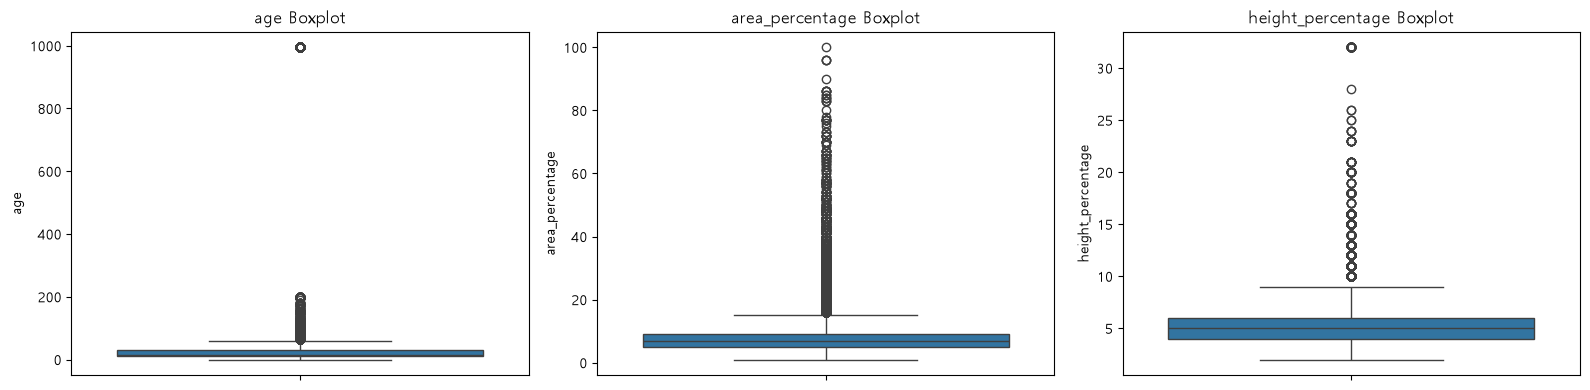

In [14]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cols = [
    "age",
    "area_percentage",
    "height_percentage"
]

for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"{col} Boxplot")

plt.tight_layout()
plt.show()


In [15]:

category_cols = [
    "land_surface_condition",
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "legal_ownership_status"
]

for col in category_cols:
    print(f"\n========== {col} ==========")

    print("고유값 수:", df[col].nunique())

    print("값별 건수:")
    print(df[col].value_counts(dropna=False))

    print("값별 비율(%):")
    print(
        df[col].value_counts(
            normalize=True,
            dropna=False
        ).mul(100).round(2)
    )



========== land_surface_condition ==========
고유값 수: 3
값별 건수:
land_surface_condition
t    173392
n     28421
o      6667
Name: count, dtype: int64
값별 비율(%):
land_surface_condition
t    83.17
n    13.63
o     3.20
Name: proportion, dtype: float64

========== foundation_type ==========
고유값 수: 5
값별 건수:
foundation_type
r    175259
w     12129
u     11436
i      8465
h      1191
Name: count, dtype: int64
값별 비율(%):
foundation_type
r    84.07
w     5.82
u     5.49
i     4.06
h     0.57
Name: proportion, dtype: float64

========== roof_type ==========
고유값 수: 3
값별 건수:
roof_type
n    146185
q     49319
x     12976
Name: count, dtype: int64
값별 비율(%):
roof_type
n    70.12
q    23.66
x     6.22
Name: proportion, dtype: float64

========== ground_floor_type ==========
고유값 수: 5
값별 건수:
ground_floor_type
f    167644
x     20029
v     19629
z       783
m       395
Name: count, dtype: int64
값별 비율(%):
ground_floor_type
f    80.41
x     9.61
v     9.42
z     0.38
m     0.19
Name: proportion, dtype: float64

In [16]:

binary_cols = [
    col for col in df.columns
    if col.startswith("has_")
]

# 0/1 외의 값이 있는지 검증
binary_validation = pd.DataFrame({
    "컬럼명": binary_cols,
    "고유값": [
        sorted(df[col].dropna().unique().tolist())
        for col in binary_cols
    ]
})

display(binary_validation)

# 1의 비율
binary_ratio = (
    df[binary_cols]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .round(2)
)

display(binary_ratio.to_frame("사용 비율(%)"))


,컬럼명,고유값
0,has_superstructure_adobe_mud,"[0, 1]"
1,has_superstructure_mud_mortar_stone,"[0, 1]"
2,has_superstructure_stone_flag,"[0, 1]"
3,has_superstructure_cement_mortar_stone,"[0, 1]"
4,has_superstructure_mud_mortar_brick,"[0, 1]"
5,has_superstructure_cement_mortar_brick,"[0, 1]"
6,has_superstructure_timber,"[0, 1]"
7,has_superstructure_bamboo,"[0, 1]"
8,has_superstructure_rc_non_engineered,"[0, 1]"
9,has_superstructure_rc_engineered,"[0, 1]"


,사용 비율(%)
has_superstructure_mud_mortar_stone,76.16
has_superstructure_timber,25.50
has_secondary_use,11.18
has_superstructure_adobe_mud,8.89
has_superstructure_bamboo,8.53
has_superstructure_cement_mortar_brick,7.51
has_superstructure_mud_mortar_brick,6.85
has_secondary_use_agriculture,6.40
has_superstructure_rc_non_engineered,4.28
has_superstructure_stone_flag,3.42


In [17]:

target_count = (
    df["damage_grade"]
    .value_counts()
    .sort_index()
)

target_ratio = (
    df["damage_grade"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "건수": target_count,
    "비율(%)": target_ratio
})

display(target_summary)

# 최대 클래스 / 최소 클래스 비율
imbalance_ratio = target_count.max() / target_count.min()

print("최대/최소 클래스 비율:", round(imbalance_ratio, 2))


,건수,비율(%)
damage_grade,,
1,20099,9.64
2,118607,56.89
3,69774,33.47


최대/최소 클래스 비율: 5.9


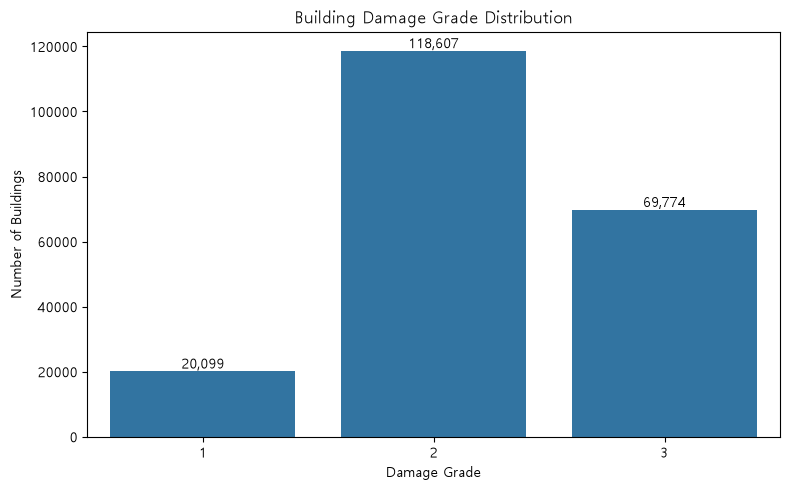

In [18]:

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="damage_grade",
    order=[1, 2, 3]
)

plt.title("Building Damage Grade Distribution")
plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [19]:

material_cols = [
    col for col in df.columns
    if col.startswith("has_superstructure_")
]

material_summary = pd.DataFrame({
    "건축물 수": df[material_cols].sum(),
    "사용 비율(%)": (
        df[material_cols].mean() * 100
    ).round(2)
})

material_summary = material_summary.sort_values(
    by="건축물 수",
    ascending=False
)

display(material_summary)


,건축물 수,사용 비율(%)
has_superstructure_mud_mortar_stone,158774,76.16
has_superstructure_timber,53163,25.50
has_superstructure_adobe_mud,18529,8.89
has_superstructure_bamboo,17783,8.53
has_superstructure_cement_mortar_brick,15658,7.51
has_superstructure_mud_mortar_brick,14276,6.85
has_superstructure_rc_non_engineered,8922,4.28
has_superstructure_stone_flag,7129,3.42
has_superstructure_cement_mortar_stone,3804,1.82
has_superstructure_rc_engineered,3300,1.58


,건축 재료,건축물 수,3등급 비율(%)
2,stone_flag,7129,47.51
1,mud_mortar_stone,158774,38.16
0,adobe_mud,18529,37.41
4,mud_mortar_brick,14276,30.79
6,timber,53163,28.11
10,other,3121,25.28
7,bamboo,17783,23.91
3,cement_mortar_stone,3804,14.27
8,rc_non_engineered,8922,12.84
5,cement_mortar_brick,15658,5.54


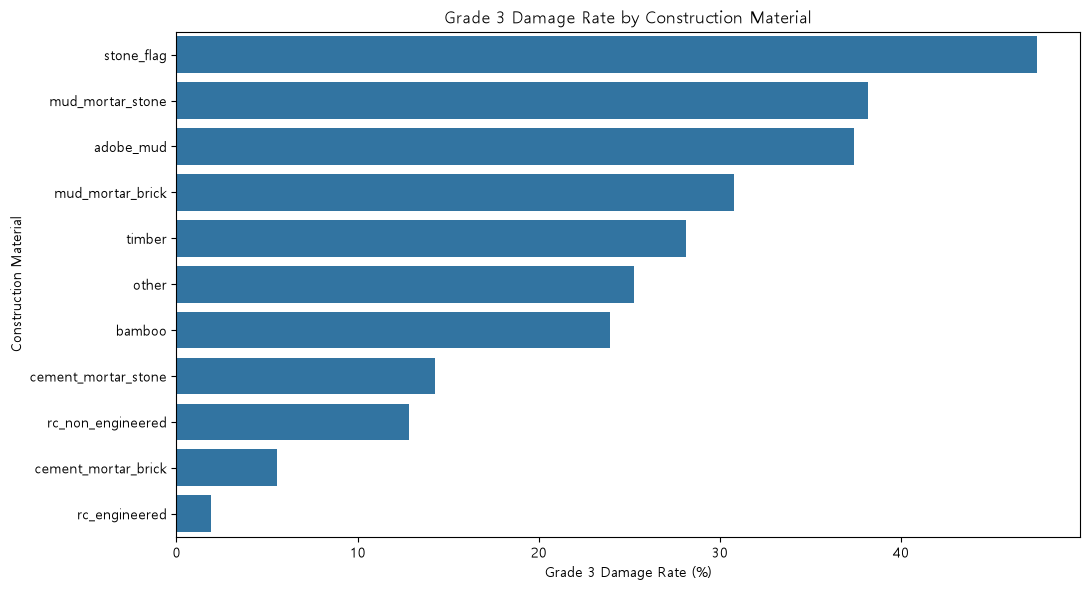

In [20]:

material_damage = []

for col in material_cols:
    selected = df[df[col] == 1]

    grade3_ratio = (
        selected["damage_grade"].eq(3).mean() * 100
        if len(selected) > 0
        else np.nan
    )

    material_damage.append({
        "건축 재료": col.replace("has_superstructure_", ""),
        "건축물 수": len(selected),
        "3등급 비율(%)": round(grade3_ratio, 2)
    })

material_damage_df = pd.DataFrame(material_damage)

material_damage_df = material_damage_df.sort_values(
    by="3등급 비율(%)",
    ascending=False
)

display(material_damage_df)

# 시각화

plt.figure(figsize=(11, 6))

sns.barplot(
    data=material_damage_df,
    x="3등급 비율(%)",
    y="건축 재료"
)

plt.title("Grade 3 Damage Rate by Construction Material")
plt.xlabel("Grade 3 Damage Rate (%)")
plt.ylabel("Construction Material")

plt.tight_layout()
plt.show()


In [21]:
import pandas as pd

# 현재 만들어져 있는 데이터프레임 확인
for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)

df_main (208480, 40)
df (208480, 40)
column_summary (40, 7)
missing_df (40, 2)
outlier_df (5, 8)
outlier_check (7, 3)
age_outlier (1716, 40)
binary_validation (22, 2)
target_summary (3, 2)
material_summary (11, 2)
selected (3121, 40)
material_damage_df (11, 3)


In [22]:

# 원본 보호
df_eda = df.copy()

# 연령 구간 정의
bins = [-1, 10, 30, 50, 100, np.inf]

labels = [
    "0~10년",
    "11~30년",
    "31~50년",
    "51~100년",
    "100년 초과"
]

df_eda["age_group"] = pd.cut(
    df_eda["age"],
    bins=bins,
    labels=labels
)

# 995는 의미 확인 전까지 별도 구분
df_eda["age_group"] = (
    df_eda["age_group"]
    .cat.add_categories(["995 별도 확인"])
)

df_eda.loc[
    df_eda["age"] == 995,
    "age_group"
] = "995 별도 확인"

display(df_eda["age_group"].value_counts())


age_group
11~30년       88520
0~10년        78898
31~50년       26475
51~100년      12871
995 별도 확인     1125
100년 초과        591
Name: count, dtype: int64

,건축 재료,건축물 수,2등급 비율(%)
순위,,,
1,cement_mortar_stone,3804,68.24
2,mud_mortar_brick,14276,65.75
3,bamboo,17783,63.30
4,timber,53163,60.34
5,adobe_mud,18529,60.00
6,cement_mortar_brick,15658,58.22
7,other,3121,57.48
8,mud_mortar_stone,158774,57.43
9,rc_non_engineered,8922,52.47


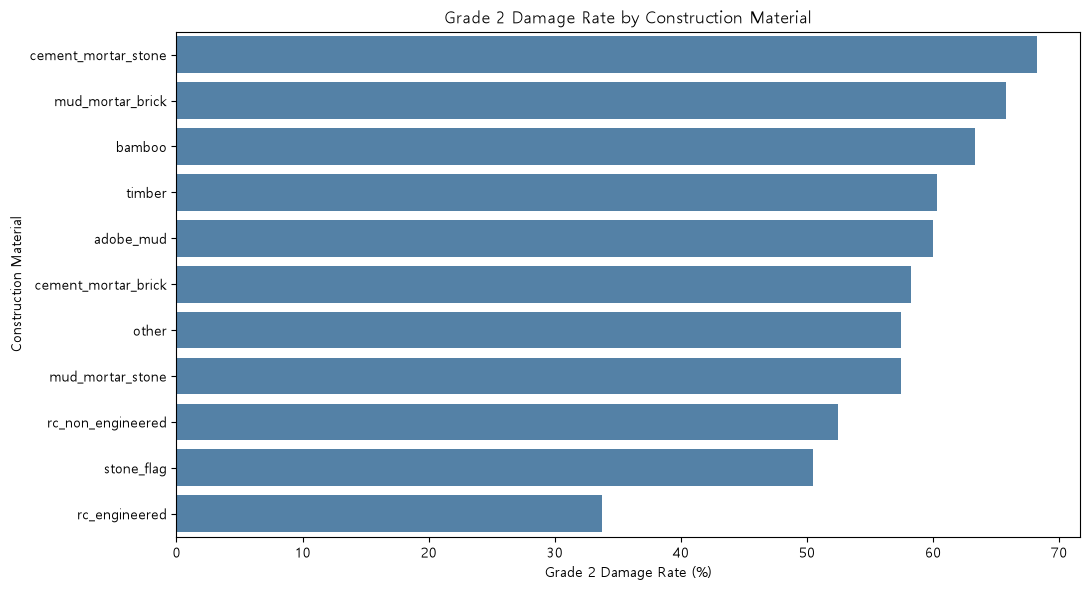

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 건축 재료 컬럼 정의
material_cols = [
    col for col in df.columns
    if col.startswith("has_superstructure_")
]

# 2. 재료별 2등급 피해 비율 계산
material_damage2 = []

for col in material_cols:
    selected = df[df[col] == 1]

    grade2_ratio = (
        selected["damage_grade"].eq(2).mean() * 100
        if len(selected) > 0
        else np.nan
    )

    material_damage2.append({
        "건축 재료": col.replace("has_superstructure_", ""),
        "건축물 수": len(selected),
        "2등급 비율(%)": round(grade2_ratio, 2)
    })

# 3. 데이터프레임 생성
material_damage2_df = pd.DataFrame(material_damage2)

# 4. 2등급 피해 비율 기준 내림차순 정렬
material_damage2_df = material_damage2_df.sort_values(
    by="2등급 비율(%)",
    ascending=False
).reset_index(drop=True)

# 5. 순위 표시
material_damage2_df.index = material_damage2_df.index + 1
material_damage2_df.index.name = "순위"

display(material_damage2_df)

# 6. 시각화
plt.figure(figsize=(11, 6))

sns.barplot(
    data=material_damage2_df,
    x="2등급 비율(%)",
    y="건축 재료",
    color="steelblue"
)

plt.title("Grade 2 Damage Rate by Construction Material")
plt.xlabel("Grade 2 Damage Rate (%)")
plt.ylabel("Construction Material")

plt.tight_layout()
plt.show()

damage_grade,1,2,3
age_group,,,
0~10년,17.40,54.91,27.69
11~30년,5.97,57.75,36.28
31~50년,2.78,58.04,39.18
51~100년,1.52,60.24,38.25
100년 초과,1.18,64.13,34.69
995 별도 확인,13.07,58.76,28.18


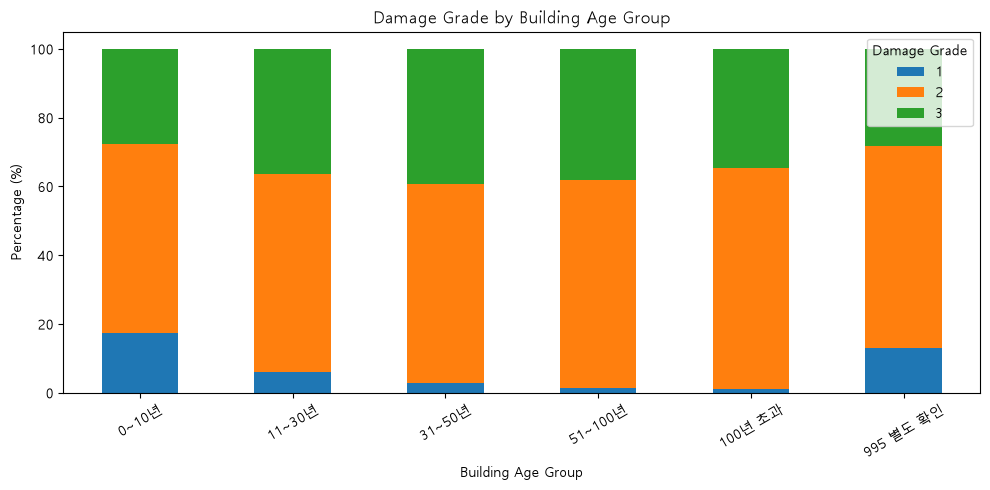

In [24]:

age_damage = pd.crosstab(
    df_eda["age_group"],
    df_eda["damage_grade"],
    normalize="index"
).mul(100).round(2)

display(age_damage)

age_damage.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Damage Grade by Building Age Group")
plt.xlabel("Building Age Group")
plt.ylabel("Percentage (%)")
plt.legend(title="Damage Grade")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


,전체_건축물,심한_피해_건물,3등급_비율(%)
geo_level_1_id,,,
17,17370,14013,80.67
18,2530,1858,73.44
21,11864,6897,58.13
8,15331,7980,52.05
27,10015,4845,48.38
28,208,83,39.90
10,17742,7062,39.80
11,6610,2548,38.55
3,6081,2250,37.00


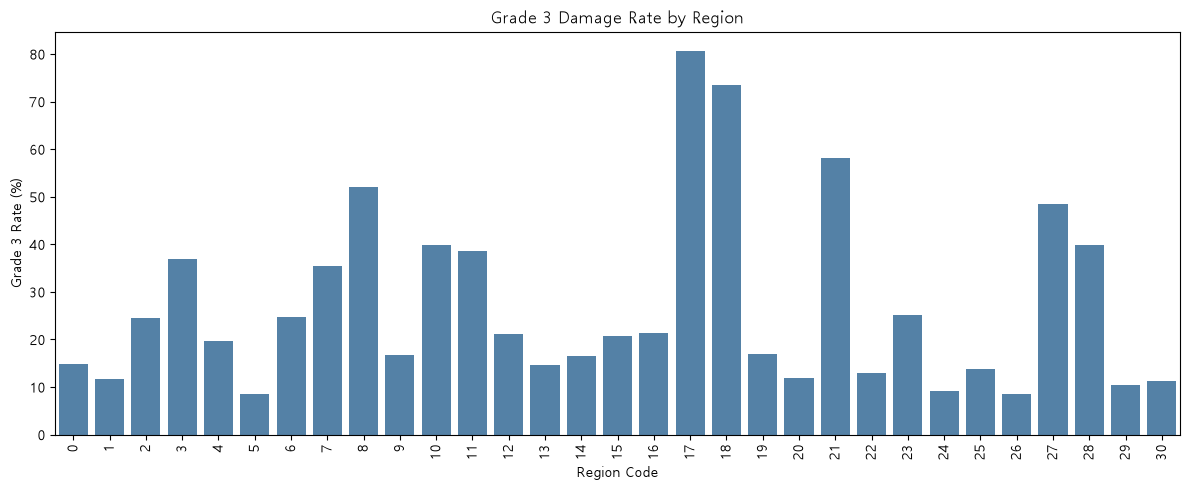

In [25]:

region_summary = (
    df.groupby("geo_level_1_id")
    .agg(
        전체_건축물=("building_id", "count"),
        심한_피해_건물=(
            "damage_grade",
            lambda x: (x == 3).sum()
        )
    )
)

region_summary["3등급_비율(%)"] = (
    region_summary["심한_피해_건물"]
    / region_summary["전체_건축물"]
    * 100
).round(2)

region_summary = region_summary.sort_values(
    "3등급_비율(%)",
    ascending=False
)

display(region_summary)

# 지역별 심한 피해 비율
plt.figure(figsize=(12, 5))

sns.barplot(
    data=region_summary.reset_index(),
    x="geo_level_1_id",
    y="3등급_비율(%)",
    color="steelblue"
)

plt.title("Grade 3 Damage Rate by Region")
plt.xlabel("Region Code")
plt.ylabel("Grade 3 Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


,전체_건축물,2grade,3grade,2grade_비율(%),3grade_비율(%)
geo_level_1_id,,,,,
29,329,288,34,87.54,10.33
30,2103,1677,239,79.74,11.36
25,4536,3529,628,77.80,13.84
0,3212,2476,479,77.09,14.91
4,11605,8894,2275,76.64,19.60
5,2190,1654,187,75.53,8.54
22,5007,3711,652,74.12,13.02
16,3443,2541,739,73.80,21.46
1,2160,1584,252,73.33,11.67


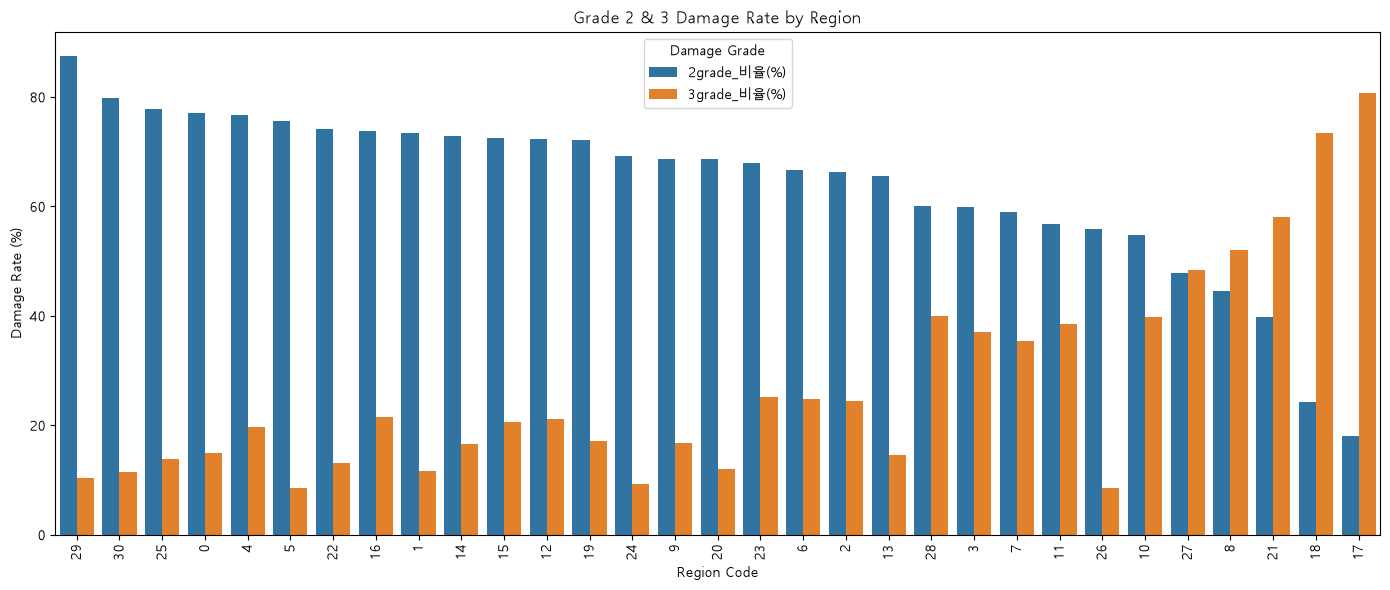

In [26]:

# 1. 지역별 2등급, 3등급 건축물 수 집계
region_summary = (
    df.groupby("geo_level_1_id")
    .agg(
        전체_건축물=("building_id", "count"),
        # [v2] 숫자로 시작하는 이름은 키워드 인자로 쓸 수 없어 원본에서 SyntaxError
        **{
            "2grade": ("damage_grade", lambda x: (x == 2).sum()),
            "3grade": ("damage_grade", lambda x: (x == 3).sum())
        }
    )
)

# 2. 지역별 피해등급 비율 계산
region_summary["2grade_비율(%)"] = (
    region_summary["2grade"]
    / region_summary["전체_건축물"]
    * 100
).round(2)

region_summary["3grade_비율(%)"] = (
    region_summary["3grade"]
    / region_summary["전체_건축물"]
    * 100
).round(2)

# 3. 2등급 비율이 높은 순서대로 정렬
region_summary = region_summary.sort_values(
    "2grade_비율(%)",
    ascending=False
)

# 4. 결과 표 출력
display(region_summary)


# 5. 그래프용 데이터 변환
plot_df = region_summary.reset_index().melt(
    id_vars="geo_level_1_id",
    value_vars=["2grade_비율(%)", "3grade_비율(%)"],
    var_name="피해등급",
    value_name="비율(%)"
)

# 6. 지역별 2등급, 3등급 비교 막대그래프
plt.figure(figsize=(14, 6))

sns.barplot(
    data=plot_df,
    x="geo_level_1_id",
    y="비율(%)",
    hue="피해등급",
    order=region_summary.index.tolist()
)

plt.title("Grade 2 & 3 Damage Rate by Region")
plt.xlabel("Region Code")
plt.ylabel("Damage Rate (%)")
plt.xticks(rotation=90)
plt.legend(title="Damage Grade")
plt.tight_layout()
plt.show()


In [27]:

# 컬럼별 최종 진단표
final_summary = pd.DataFrame({
    "컬럼명": df.columns,
    "데이터 타입": df.dtypes.astype(str).values,
    "결측치 수": df.isna().sum().values,
    "결측률(%)": (df.isna().mean() * 100).round(2).values,
    "고유값 수": df.nunique(dropna=False).values
})

# 전체 품질 요약
quality_summary = pd.DataFrame({
    "점검 항목": [
        "전체 행 수",
        "전체 컬럼 수",
        "전체 결측치 수",
        "완전 중복 행 수",
        "건물 ID 중복 수",
        "ID 제외 동일 행 수",
        "age=995 건수"
    ],
    "결과": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["building_id"].duplicated().sum()),
        int(df.duplicated(
            subset=df.columns.drop("building_id")
        ).sum()),
        int((df["age"] == 995).sum())
    ]
})

# 진단 결과 저장
output_dir = OUT_DIR  # [v2]
output_dir.mkdir(exist_ok=True)

with pd.ExcelWriter(
    output_dir / "nepal_data_diagnosis.xlsx"
) as writer:
    final_summary.to_excel(
        writer, sheet_name="컬럼 진단", index=False
    )
    quality_summary.to_excel(
        writer, sheet_name="품질 요약", index=False
    )
    outlier_df.to_excel(
        writer, sheet_name="IQR 이상치", index=False
    )
    target_summary.to_excel(
        writer, sheet_name="피해등급 분포"
    )
    material_damage_df.to_excel(
        writer, sheet_name="재료별 피해", index=False
    )
    region_summary.to_excel(
        writer, sheet_name="지역별 피해"
    )

print("진단 결과 엑셀 저장 완료")


진단 결과 엑셀 저장 완료


클래스 불균형 확인


In [28]:
print (df["damage_grade"].value_counts)
print(
    df["damage_grade"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

<bound method IndexOpsMixin.value_counts of 0         2
1         3
2         3
3         2
4         1
         ..
208475    2
208476    2
208477    3
208478    3
208479    3
Name: damage_grade, Length: 208480, dtype: int64>
damage_grade
1     9.640733
2    56.891309
3    33.467959
Name: proportion, dtype: float64


In [29]:

import pandas as pd

# 1. damage_grade 2, 3만 추출
df_grade = df[df["damage_grade"].isin([2, 3])]

# 2. geo_level_1_id별 피해등급 건수 집계
region_summary = (
    df_grade
    .groupby(["geo_level_1_id", "damage_grade"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[2, 3], fill_value=0)
)

# 3. 컬럼명 변경
region_summary.columns = [
    "damage_grade_2",
    "damage_grade_3"
]

# 4. 피해등급 2 순위
grade2_rank = (
    region_summary
    .sort_values("damage_grade_2", ascending=False)
    .reset_index()
)

grade2_rank.insert(
    0, "순위", range(1, len(grade2_rank) + 1)
)

# 5. 피해등급 3 순위
grade3_rank = (
    region_summary
    .sort_values("damage_grade_3", ascending=False)
    .reset_index()
)

grade3_rank.insert(
    0, "순위", range(1, len(grade3_rank) + 1)
)

# 6. 각각 출력
print("===== damage_grade 2 지역별 순위 =====")
display(grade2_rank[["순위", "geo_level_1_id", "damage_grade_2"]])

print("===== damage_grade 3 지역별 순위 =====")
display(grade3_rank[["순위", "geo_level_1_id", "damage_grade_3"]])


===== damage_grade 2 지역별 순위 =====


,순위,geo_level_1_id,damage_grade_2
0,1,6,12984
1,2,26,10087
2,3,10,9706
3,4,20,9467
4,5,7,8975
5,6,4,8894
6,7,8,6833
7,8,13,5084
8,9,27,4788
9,10,21,4711


===== damage_grade 3 지역별 순위 =====


,순위,geo_level_1_id,damage_grade_3
0,1,17,14013
1,2,8,7980
2,3,10,7062
3,4,21,6897
4,5,7,5394
5,6,27,4845
6,7,6,4823
7,8,11,2548
8,9,4,2275
9,10,3,2250


In [30]:
# 지역별 전체 건축물 수
region_total = df.groupby("geo_level_1_id").size()

# 피해등급 2, 3 비율 계산
region_summary["2등급_비율(%)"] = (
    region_summary["damage_grade_2"] / region_total * 100
).round(2)

region_summary["3등급_비율(%)"] = (
    region_summary["damage_grade_3"] / region_total * 100
).round(2)

# 2등급 비율 순위
display(
    region_summary
    .sort_values("2등급_비율(%)", ascending=False)
    [["damage_grade_2", "2등급_비율(%)"]]
)

# 3등급 비율 순위
display(
    region_summary
    .sort_values("3등급_비율(%)", ascending=False)
    [["damage_grade_3", "3등급_비율(%)"]]
)

,damage_grade_2,2등급_비율(%)
geo_level_1_id,,
29,288,87.54
30,1677,79.74
25,3529,77.80
0,2476,77.09
4,8894,76.64
5,1654,75.53
22,3711,74.12
16,2541,73.80
1,1584,73.33


,damage_grade_3,3등급_비율(%)
geo_level_1_id,,
17,14013,80.67
18,1858,73.44
21,6897,58.13
8,7980,52.05
27,4845,48.38
28,83,39.90
10,7062,39.80
11,2548,38.55
3,2250,37.00


In [31]:

import pandas as pd

# 1. 원본 데이터 불러오기
df_original = pd.read_csv(DEV_CSV)  # [v2]

# 2. 분석용 복사본 생성
df = df_original.copy()

# 3. 복사본의 피해등급별 건수 확인
print(df["damage_grade"].value_counts())


damage_grade
2    118607
3     69774
1     20099
Name: count, dtype: int64


In [32]:
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.width", 200)
df = df_original.copy()

# 대지역 + 중지역 + 소지역 -> 하나의 변수
df["geo_combined"] = (
    df["geo_level_1_id"].astype(str) + "-"
    + df["geo_level_2_id"].astype(str) + "-"
    + df["geo_level_3_id"].astype(str)
)

print(f"geo_level_1  : {df['geo_level_1_id'].nunique():>6,}")
print(f"geo_level_2  : {df['geo_level_2_id'].nunique():>6,}")
print(f"geo_level_3  : {df['geo_level_3_id'].nunique():>6,}")
print(f"geo_combined : {df['geo_combined'].nunique():>6,}")

# 완전 중첩 구조인지 확인
nested = df.groupby("geo_level_3_id")[["geo_level_1_id", "geo_level_2_id"]].nunique().max()
print(f"\n소지역 하나가 속한 상위 지역 수: 대 {nested.iloc[0]}, 중 {nested.iloc[1]}")

geo_level_1  :     31
geo_level_2  :  1,408
geo_level_3  : 11,353
geo_combined : 11,353

소지역 하나가 속한 상위 지역 수: 대 1, 중 1


In [33]:
def chi2_test(a, b, name_a, name_b, verbose=True):
    observed = pd.crosstab(a, b)

    chi2, p_value, dof, expected = stats.chi2_contingency(
        observed,
        correction=False
    )

    # 교안: 모든 칸의 기대빈도가 5 이상일 때 신뢰할 수 있다
    small = (expected < 5).sum()
    cells = expected.size

    if verbose:
        print(f"\n[{name_a} x {name_b}]")
        print(f"  교차표 크기        : {observed.shape[0]} x {observed.shape[1]}")
        print(f"  카이제곱 통계량    : {chi2:,.1f}")
        print(f"  p-value            : {p_value:.4f}")
        print(f"  자유도             : {dof:,}")
        print(f"  기대빈도 5 미만 칸 : {small:,} / {cells:,} "
              f"({small/cells*100:.1f}%)  → {'신뢰 가능' if small == 0 else '신뢰 불가'}")
        print(f"  판단: {'두 변수는 관련이 있다' if p_value < 0.05 else '관련 있다고 보기 어렵다'}")

    return {"chi2": chi2, "p": p_value, "dof": dof, "작은칸비율": small / cells}


chi2_test(df["geo_combined"],   df["damage_grade"], "geo_combined",   "damage_grade")
chi2_test(df["geo_level_1_id"], df["damage_grade"], "geo_level_1_id", "damage_grade")


[geo_combined x damage_grade]
  교차표 크기        : 11353 x 3
  카이제곱 통계량    : 148,997.3
  p-value            : 0.0000
  자유도             : 22,704
  기대빈도 5 미만 칸 : 21,664 / 34,059 (63.6%)  → 신뢰 불가
  판단: 두 변수는 관련이 있다

[geo_level_1_id x damage_grade]
  교차표 크기        : 31 x 3
  카이제곱 통계량    : 57,883.7
  p-value            : 0.0000
  자유도             : 60
  기대빈도 5 미만 칸 : 0 / 93 (0.0%)  → 신뢰 가능
  판단: 두 변수는 관련이 있다


{'chi2': np.float64(57883.67706415941),
 'p': np.float64(0.0),
 'dof': 60,
 '작은칸비율': np.float64(0.0)}

In [34]:
import numpy as np
import pandas as pd
from scipy import stats

GRADE_NAME = {1: "1등급(경미)", 2: "2등급(중간)", 3: "3등급(거의전파)"}


def chi2_test(a, b, name_a, name_b, verbose=True, top=12):
    """카이제곱 독립성 검정 + 등급별 분해.

    교안 3장 1강 방식으로 전체 검정을 한 뒤,
    (1) 칸별 표준화 잔차로 '어느 등급이 차이를 만드는가'
    (2) 각 등급 vs 나머지 검정으로 '그 등급만 따로 보면 어떤가'
    를 추가로 본다.
    """
    observed = pd.crosstab(a, b)

    chi2, p_value, dof, expected = stats.chi2_contingency(
        observed, correction=False
    )
    expected = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

    small = int((expected < 5).sum().sum())
    cells = expected.size

    # 표준화 잔차 = (관측 - 기대) / sqrt(기대)
    #   +2 이상 : 그 등급이 기대보다 많다
    #   -2 이하 : 그 등급이 기대보다 적다
    resid = (observed - expected) / np.sqrt(expected)

    # 칸별 카이제곱 기여도 (전부 더하면 전체 chi2)
    contrib = (observed - expected) ** 2 / expected

    by_grade = pd.DataFrame({
        "관측합": observed.sum(axis=0),
        "기대합": expected.sum(axis=0).round(0),
        "chi2기여": contrib.sum(axis=0).round(1),
        "기여율%": (contrib.sum(axis=0) / chi2 * 100).round(1),
        "최대잔차": resid.abs().max(axis=0).round(2),
    })
    by_grade.index = [GRADE_NAME.get(i, i) for i in by_grade.index]

    # 등급별 (해당 등급 vs 나머지) 검정
    ovr = []
    for g in observed.columns:
        tbl = pd.crosstab(a, (b == g).map({True: f"{g}등급", False: "나머지"}))
        c2, p2, d2, e2 = stats.chi2_contingency(tbl, correction=False)
        n = tbl.values.sum()
        r, k = tbl.shape
        v = np.sqrt((c2 / n) / max(min(r - 1, k - 1), 1))
        ovr.append({
            "등급": GRADE_NAME.get(g, g),
            "해당건수": int((b == g).sum()),
            "비율%": round((b == g).mean() * 100, 2),
            "chi2": round(c2, 1),
            "p-value": round(p2, 4),
            "CramersV": round(v, 4),
            "기대<5": int((e2 < 5).sum()),
        })
    ovr = pd.DataFrame(ovr)

    if verbose:
        print("=" * 76)
        print(f"[{name_a} x {name_b}]")
        print("=" * 76)
        print(f"  교차표 크기        : {observed.shape[0]} x {observed.shape[1]}")
        print(f"  카이제곱 통계량    : {chi2:,.1f}")
        print(f"  p-value            : {p_value:.4f}")
        print(f"  자유도             : {dof:,}")
        print(f"  기대빈도 5 미만 칸 : {small:,} / {cells:,} "
              f"({small/cells*100:.1f}%)  → {'신뢰 가능' if small == 0 else '신뢰 불가'}")
        print(f"  판단: {'두 변수는 관련이 있다' if p_value < 0.05 else '관련 있다고 보기 어렵다'}")

        print(f"\n── 등급별 카이제곱 기여도 ──")
        print(by_grade.to_string())

        print(f"\n── 등급별 (해당 등급 vs 나머지) 검정 ──")
        print(ovr.to_string(index=False))

        if observed.shape[0] <= top:
            print(f"\n── 관측빈도 ──")
            o = observed.copy(); o.columns = [GRADE_NAME.get(c, c) for c in o.columns]
            print(o.to_string())
            print(f"\n── 기대빈도 ──")
            e = expected.round(0); e.columns = [GRADE_NAME.get(c, c) for c in e.columns]
            print(e.to_string())
            print(f"\n── 표준화 잔차 (|2| 넘으면 눈여겨볼 칸) ──")
            r_ = resid.round(1); r_.columns = [GRADE_NAME.get(c, c) for c in r_.columns]
            print(r_.to_string())
        else:
            print(f"\n── 표준화 잔차 상위 {top}칸 (범주가 {observed.shape[0]}개라 요약) ──")
            s = resid.stack().rename("잔차").reset_index()
            s.columns = [name_a, "등급", "잔차"]
            s["등급"] = s["등급"].map(GRADE_NAME).fillna(s["등급"])
            s["관측"] = observed.stack().values
            s["기대"] = expected.stack().round(1).values
            print(s.reindex(s["잔차"].abs().sort_values(ascending=False).index)
                   .head(top).to_string(index=False))

    return {"chi2": chi2, "p": p_value, "dof": dof, "작은칸비율": small / cells,
            "등급별기여": by_grade, "등급별검정": ovr, "잔차": resid}


# 실행
chi2_test(df["foundation_type"], df["damage_grade"], "foundation_type", "damage_grade")
chi2_test(df["geo_level_1_id"],  df["damage_grade"], "geo_level_1_id",  "damage_grade", top=5)
chi2_test(df["geo_combined"],    df["damage_grade"], "geo_combined",    "damage_grade", top=8)

[foundation_type x damage_grade]
  교차표 크기        : 5 x 3
  카이제곱 통계량    : 38,883.0
  p-value            : 0.0000
  자유도             : 8
  기대빈도 5 미만 칸 : 0 / 15 (0.0%)  → 신뢰 가능
  판단: 두 변수는 관련이 있다

── 등급별 카이제곱 기여도 ──
              관측합       기대합   chi2기여  기여율%    최대잔차
1등급(경미)     20099   20099.0  31587.8  81.2  139.14
2등급(중간)    118607  118607.0    502.1   1.3   19.08
3등급(거의전파)   69774   69774.0   6793.1  17.5   49.81

── 등급별 (해당 등급 vs 나머지) 검정 ──
       등급   해당건수   비율%    chi2  p-value  CramersV  기대<5
  1등급(경미)  20099  9.64 34958.0      0.0    0.4095     0
  2등급(중간) 118607 56.89  1164.7      0.0    0.0747     0
3등급(거의전파)  69774 33.47 10210.3      0.0    0.2213     0

── 관측빈도 ──
                 1등급(경미)  2등급(중간)  3등급(거의전파)
foundation_type                             
h                    304      454        433
i                   4791     3492        182
r                   8541   100366      66352
u                   2965     6875       1596
w                   3498     7420       1211

── 

[geo_combined x damage_grade]
  교차표 크기        : 11353 x 3
  카이제곱 통계량    : 148,997.3
  p-value            : 0.0000
  자유도             : 22,704
  기대빈도 5 미만 칸 : 21,664 / 34,059 (63.6%)  → 신뢰 불가
  판단: 두 변수는 관련이 있다

── 등급별 카이제곱 기여도 ──
              관측합       기대합   chi2기여  기여율%   최대잔차
1등급(경미)     20099   20099.0  63505.0  42.6  44.23
2등급(중간)    118607  118607.0  29012.8  19.5   8.67
3등급(거의전파)   69774   69774.0  56479.5  37.9  12.71

── 등급별 (해당 등급 vs 나머지) 검정 ──
       등급   해당건수   비율%    chi2  p-value  CramersV  기대<5
  1등급(경미)  20099  9.64 70280.5      0.0    0.5806 14119
  2등급(중간) 118607 56.89 67301.6      0.0    0.5682 10137
3등급(거의전파)  69774 33.47 84890.7      0.0    0.6381 10665

── 표준화 잔차 상위 8칸 (범주가 11353개라 요약) ──
geo_combined      등급        잔차  관측   기대
  26-39-9133 1등급(경미) 44.228066 370 51.8
   26-39-633 1등급(경미) 33.828974 289 49.9
 10-151-7723 1등급(경미) 32.253808 224 34.5
 26-39-11440 1등급(경미) 27.735421 201 35.6
 6-1253-3073 1등급(경미) 25.911151 102 12.1
 26-39-11246 1등급(경미) 24.736344 184 35.9
2

{'chi2': np.float64(148997.30478674272),
 'p': np.float64(0.0),
 'dof': 22704,
 '작은칸비율': 0.6360726973780793,
 '등급별기여':               관측합       기대합   chi2기여  기여율%   최대잔차
 1등급(경미)     20099   20099.0  63505.0  42.6  44.23
 2등급(중간)    118607  118607.0  29012.8  19.5   8.67
 3등급(거의전파)   69774   69774.0  56479.5  37.9  12.71,
 '등급별검정':           등급    해당건수    비율%     chi2  p-value  CramersV   기대<5
 0    1등급(경미)   20099   9.64  70280.5      0.0    0.5806  14119
 1    2등급(중간)  118607  56.89  67301.6      0.0    0.5682  10137
 2  3등급(거의전파)   69774  33.47  84890.7      0.0    0.6381  10665,
 '잔차': damage_grade         1         2         3
 geo_combined                              
 0-1017-11038 -0.694289  0.685074 -0.520562
 0-1017-12133 -0.694289  0.092159  0.252476
 0-1017-3532  -0.439107  0.808271 -0.818144
 0-1017-9884  -0.439107 -0.129209  0.404135
 0-1031-10511 -1.029796  1.495820 -1.397536
 ...                ...       ...       ...
 9-973-6344   -0.537794  0.224476 -0.004031
 9-973-72

In [35]:
def cramers_v(a, b):
    """카이제곱을 0~1 로 정규화. 카이제곱은 표본 크기에 비례해 커지므로
    변수끼리 직접 비교할 수 없다. Cramer's V 는 비교가 가능하다."""
    observed = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(observed, correction=False)[0]
    n = observed.values.sum()
    r, k = observed.shape
    return np.sqrt((chi2 / n) / max(min(r - 1, k - 1), 1))


CAT_COLS = [
    "geo_level_1_id", "land_surface_condition", "foundation_type",
    "roof_type", "ground_floor_type", "other_floor_type",
    "position", "plan_configuration", "legal_ownership_status",
    "damage_grade",
]

vmat = pd.DataFrame(index=CAT_COLS, columns=CAT_COLS, dtype=float)
for a in CAT_COLS:
    for b in CAT_COLS:
        vmat.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

print(vmat.round(3).to_string())
print("\n해석 기준: 0.1 약함 / 0.3 보통 / 0.5 강함")

                        geo_level_1_id  land_surface_condition  foundation_type  roof_type  ground_floor_type  other_floor_type  position  plan_configuration  legal_ownership_status  damage_grade
geo_level_1_id                   1.000                   0.087            0.311      0.263              0.161             0.205     0.237               0.046                   0.147         0.373
land_surface_condition           0.087                   1.000            0.032      0.039              0.044             0.037     0.034               0.021                   0.021         0.030
foundation_type                  0.311                   0.032            1.000      0.548              0.357             0.411     0.098               0.058                   0.149         0.305
roof_type                        0.263                   0.039            0.548      1.000              0.473             0.521     0.124               0.064                   0.030         0.240
ground_floor_type   

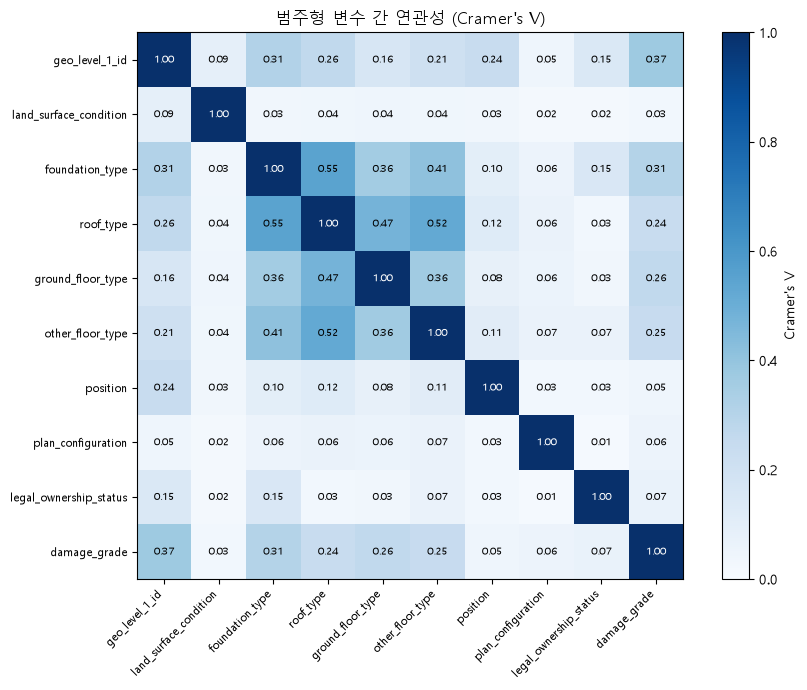

In [36]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if f in {x.name for x in fm.fontManager.ttflist}:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(vmat.values.astype(float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CAT_COLS)))
ax.set_xticklabels(CAT_COLS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(CAT_COLS)))
ax.set_yticklabels(CAT_COLS, fontsize=8)
for i in range(len(CAT_COLS)):
    for j in range(len(CAT_COLS)):
        v = vmat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                fontsize=7, color="white" if v > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Cramer's V")
ax.set_title("범주형 변수 간 연관성 (Cramer's V)")
fig.tight_layout()
plt.show()